# Does training on more recordings help?

This experiment keeps the original validation windows, quality gates and pressure-label method fixed. It adds training recordings sampled evenly across Parts 1–4 without selecting on pressure values. All additions are screened for known exact/shifted overlaps with held-out recordings before fitting.

We compare the original features, normalized features and original-plus-pulse features using the fixed RF and boosting settings from the previous experiment. Validation is exploratory; the old test is not scored. [Full results](TRAINING_EXPANSION_RESULTS.md).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
RUN=Path('outputs/training_learning_curve_oct28')
metrics=pd.read_csv(RUN/'metrics.csv')
display(pd.read_csv(RUN/'training_counts.csv'))
validation=metrics[metrics.split.eq('validation')]
display(validation.pivot(index=['level','variant','model'],columns='target',values='mae_mmHg').round(2))

,level,windows,recordings,groups
0,Original training,4013,467,466
1,Half expansion,7585,886,884
2,Full expansion,11291,1308,1303


target                                         dbp    sbp
level             variant          model                 
Full expansion    Constant         mean      10.02  18.70
                                   median    10.17  18.96
                  Normalized       Boosting   8.69  16.24
                                   RF         8.68  16.10
                  Original         Boosting   8.59  16.85
                                   RF         8.61  16.34
                  Original + pulse Boosting   8.65  16.64
                                   RF         8.55  16.12
Half expansion    Constant         mean      10.02  18.68
                                   median    10.15  18.92
                  Normalized       Boosting   8.72  16.41
                                   RF         8.76  16.45
                  Original         Boosting   8.76  16.93
                                   RF         8.61  16.63
                  Original + pulse Boosting   8.81  16.69
                                   RF         8.68  16.44
Original training Constant         mean      10.03  18.70
                                   median    10.21  18.93
                  Normalized       Boosting   8.76  16.67
                                   RF         8.75  16.75
                  Original         Boosting   8.89  17.12
                                   RF         8.83  16.86
                  Original + pulse Boosting   8.95  16.68
                                   RF         8.81  16.54

## Learning curve

The horizontal axis counts distinct training recordings. The vertical axis is validation MAE in mmHg, so lower is better. Every point uses the same validation windows. A lower training/OOF error alone would not answer this question because the training population changes as recordings are added.

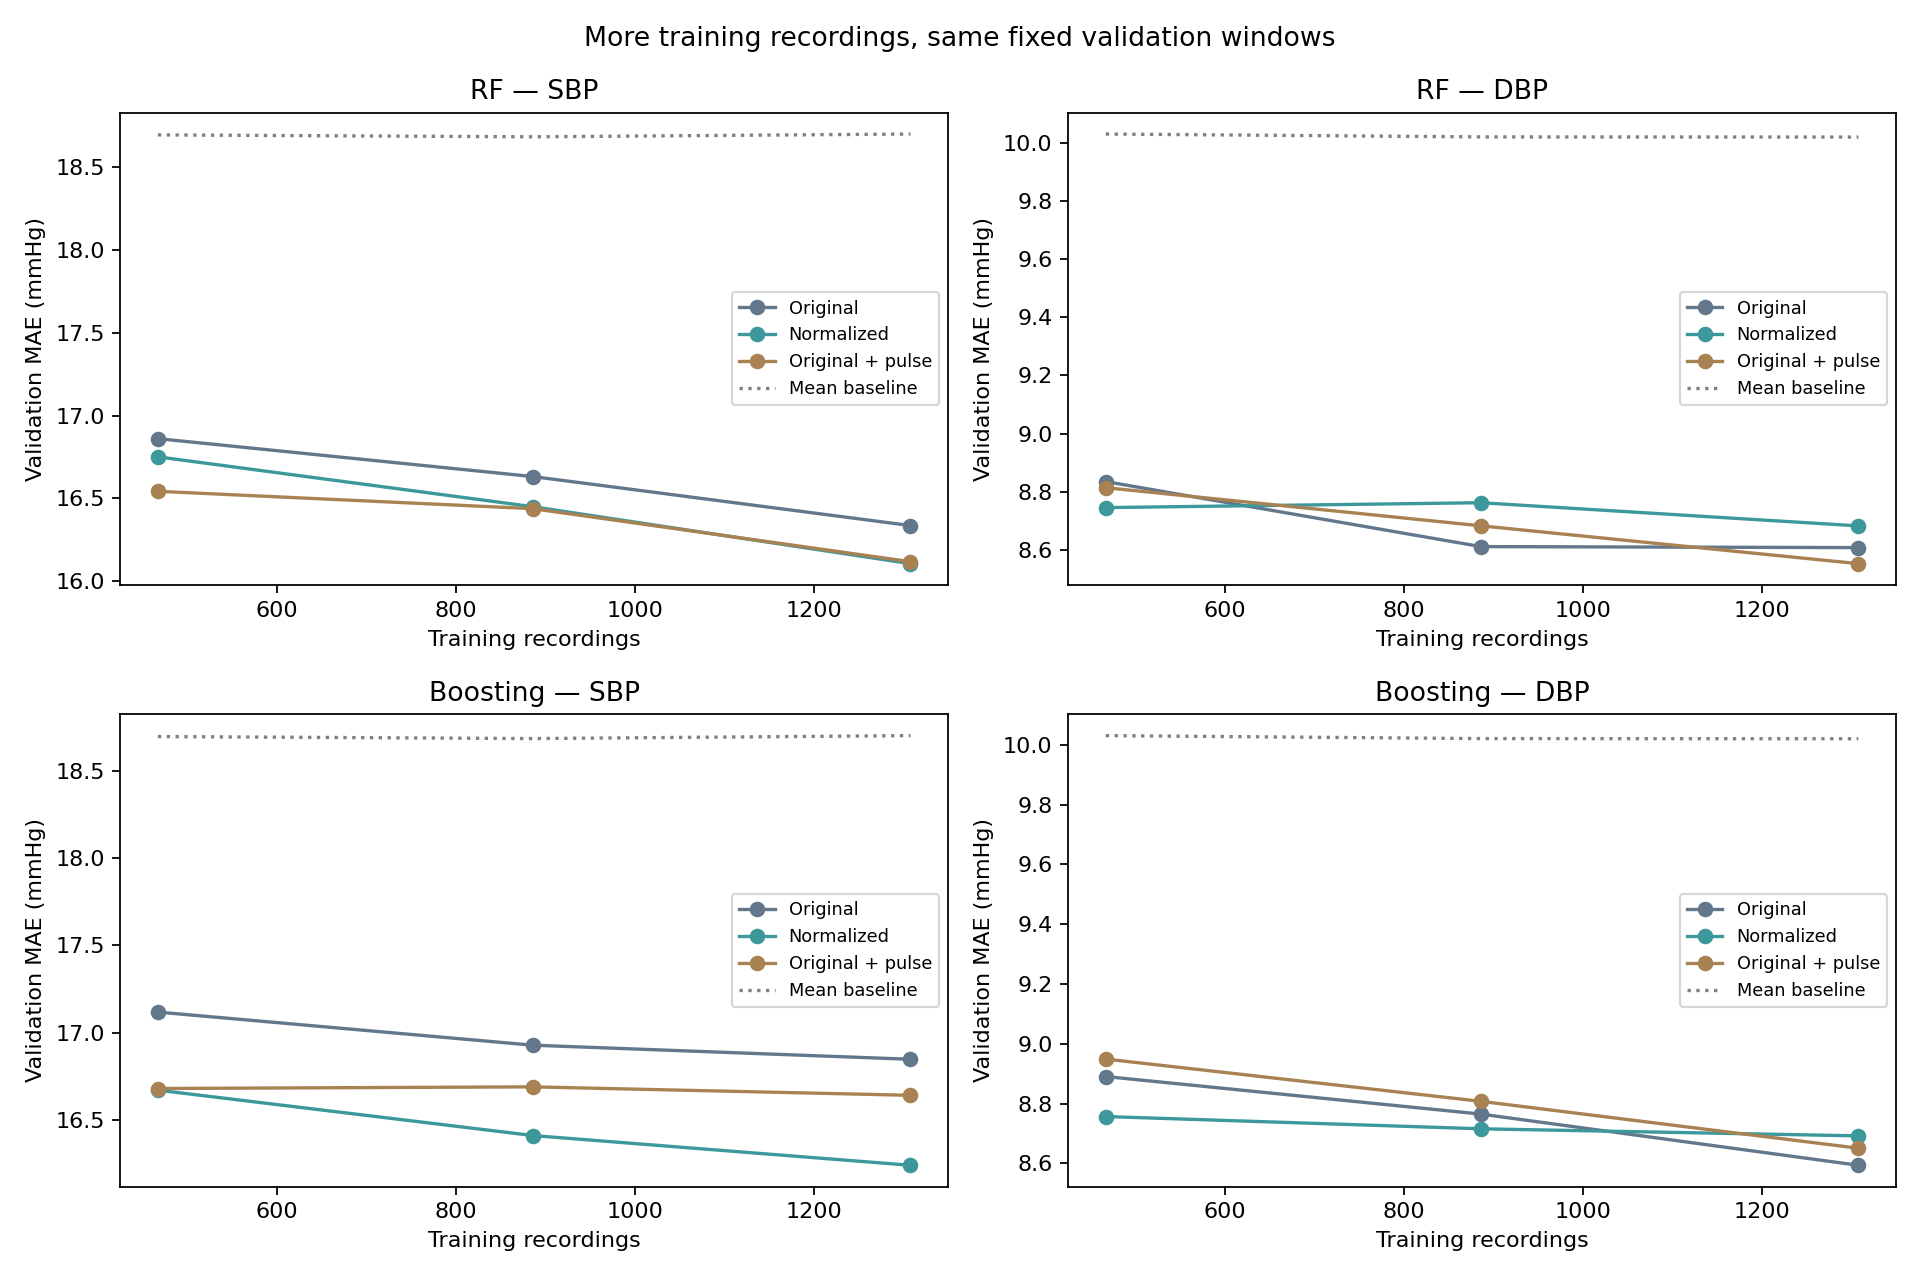

In [2]:
display(Image(filename=str(RUN/'learning_curve.png')))

## Check large errors and equal group weights

RMSE gives more weight to large misses. Equal-group MAE gives each detected overlap group the same weight instead of allowing recordings with more windows to count more. Positive paired gains mean lower equal-group MAE than the original-size model using the same features. Intervals are conditional on these fixed models and do not include all model-development uncertainty.

In [3]:
display(validation[['level','variant','model','target','rmse_mmHg','overlap_group_macro_mae']].round(2))
display(pd.read_csv(RUN/'paired_expansion_gains.csv').round(3))

,level,variant,model,target,rmse_mmHg,overlap_group_macro_mae
2,Original training,Original,RF,sbp,22.44,16.36
3,Original training,Original,RF,dbp,12.16,9.17
6,Original training,Original,Boosting,sbp,22.53,16.72
7,Original training,Original,Boosting,dbp,12.24,9.27
10,Original training,Normalized,RF,sbp,22.16,16.54
11,Original training,Normalized,RF,dbp,12.16,9.13
14,Original training,Normalized,Boosting,sbp,21.99,16.26
15,Original training,Normalized,Boosting,dbp,12.07,9.25
18,Original training,Original + pulse,RF,sbp,22.08,15.95
19,Original training,Original + pulse,RF,dbp,12.17,9.24


,model,variant,level,target,equal_group_mae_gain,ci_low,ci_high
0,RF,Original,Half expansion,sbp,0.231,-0.634,1.150
1,RF,Original,Half expansion,dbp,0.249,-0.132,0.630
2,RF,Original,Full expansion,sbp,0.521,-0.394,1.445
3,RF,Original,Full expansion,dbp,0.331,-0.046,0.698
4,RF,Normalized,Half expansion,sbp,0.338,-0.344,1.093
5,RF,Normalized,Half expansion,dbp,0.007,-0.306,0.323
6,RF,Normalized,Full expansion,sbp,0.576,-0.325,1.566
7,RF,Normalized,Full expansion,dbp,0.112,-0.303,0.540
8,RF,Original + pulse,Half expansion,sbp,-0.039,-0.901,0.845
9,RF,Original + pulse,Half expansion,dbp,0.178,-0.225,0.586


## Training-only checks

The table below evaluates out-of-fold predictions on the same original 4,013 training windows at every size. Folds are defined by overlap groups on the complete training pool and restricted to each nested training subset; the original evaluation groups stay held out inside each fold. Each model and feature condition at the same size uses the same folds. Original test records and connected training candidates are excluded from model fitting. The dataset has recording IDs, not confirmed patient IDs.

In [4]:
display(pd.read_csv(RUN/'fixed_original_oof_metrics.csv')[['level','variant','model','target','mae_mmHg','overlap_group_macro_mae']].round(2))
display(pd.read_json('outputs/training_expansion_oct28/preparation_summary.json',typ='series'))

,level,variant,model,target,mae_mmHg,overlap_group_macro_mae
0,Full expansion,Normalized,Boosting,sbp,15.42,15.59
1,Full expansion,Normalized,Boosting,dbp,7.50,7.61
2,Full expansion,Normalized,RF,sbp,15.23,15.41
3,Full expansion,Normalized,RF,dbp,7.37,7.50
4,Full expansion,Original,Boosting,sbp,15.62,15.59
5,Full expansion,Original,Boosting,dbp,7.53,7.59
6,Full expansion,Original,RF,sbp,15.46,15.46
7,Full expansion,Original,RF,dbp,7.42,7.51
8,Full expansion,Original + pulse,Boosting,sbp,15.43,15.41
9,Full expansion,Original + pulse,Boosting,dbp,7.51,7.59


new_sampled_records                           1000
new_sampled_windows                           9631
new_quality_eligible_windows                  7279
new_heldout_overlap_windows                      6
original_training_windows_excluded               0
original_training_windows                     4013
total_training_windows                       11291
total_training_records                        1308
validation_windows                             857
test_evaluated                                   0
new_quality_eligible_before_overlap           7284
new_training_windows_after_all_exclusions     7278
dtype: int64

## Reproduce

Run `expand_training_recordings.py` to prepare the additions, then `training_recording_learning_curve.py` to extract features and fit the fixed models. Both require new output directories for a new run. `summarize_training_learning_curve.py` regenerates the comparisons, chart and report from saved results. Raw MAT data and generated model binaries are not included in the upload.

A future final score needs a new untouched evaluation set. The fixed validation results here remain useful for development, but repeated inspection makes them an optimistic guide to future performance.